# ЗАГРУЗКА КУРСА ДОЛЛАРА США С САЙТА ЦБ РФ
 Что делает:
 1. Скачивает XML с курсом доллара с 2010 года по сегодня
 2. Парсит XML, вытаскивает даты и значения
 3. Сохраняет в CSV
 4. Рисует график и сохраняет PNG

Дата и время начала загрузки: 2026-09-26 07:29:40

Источник: Центральный Банк РФ
Инструмент: Курс доллара США (USD), код R01235
Показатель: Официальный курс на дату
Количество точек: 4135 (требование: >= 3000) [OK]
Период: с 2010-01-01 по 2026-09-26
Частота: ежедневная (рабочие дни)
Пропуски: 0


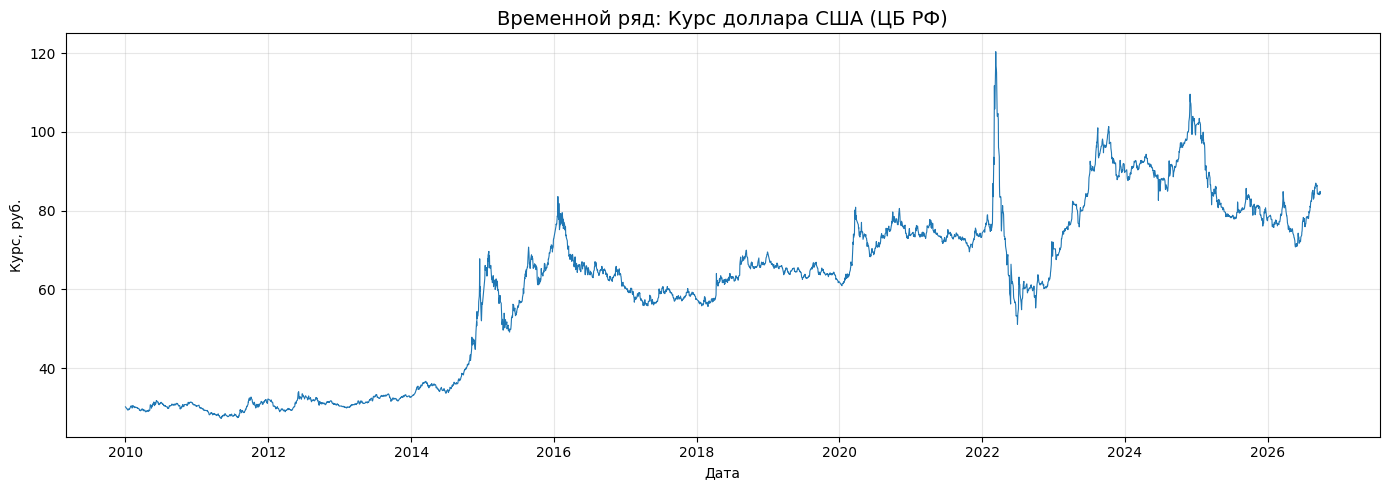

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import xml.etree.ElementTree as ET

DOWNLOAD_DATE = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Дата и время начала загрузки: {DOWNLOAD_DATE}\n")

print("Источник: Центральный Банк РФ")
print("Инструмент: Курс доллара США (USD), код R01235")
print("Показатель: Официальный курс на дату")

url_cbr = f"https://www.cbr.ru/scripts/XML_dynamic.asp?date_req1=01/01/2010&date_req2={datetime.now().strftime('%d/%m/%Y')}&VAL_NM_RQ=R01235"

response = requests.get(url_cbr, timeout=30)
response.raise_for_status()

root = ET.fromstring(response.content)

records = []
for record in root.findall('Record'):
    date_str = record.get('Date')
    value_elem = record.find('Value')

    if date_str and value_elem is not None and value_elem.text:
        value_str = value_elem.text.replace(',', '.') 
        records.append({
            'date': date_str,
            'price': float(value_str)
        })

df_cbr = pd.DataFrame(records)

if not df_cbr.empty:

    df_cbr['date'] = pd.to_datetime(df_cbr['date'], format='%d.%m.%Y')

    df_cbr = df_cbr.sort_values(by='date').reset_index(drop=True)

    csv_name_ts = "timeseries_cbr_usd_daily.csv"
    df_cbr.to_csv(csv_name_ts, index=False, encoding="utf-8-sig")

    points_status = "OK" if len(df_cbr) >= 3000 else "FAIL"
    print(f"Количество точек: {len(df_cbr)} (требование: >= 3000) [{points_status}]")
    print(f"Период: с {df_cbr['date'].min().strftime('%Y-%m-%d')} по {df_cbr['date'].max().strftime('%Y-%m-%d')}")
    print(f"Частота: ежедневная (рабочие дни)")
    print(f"Пропуски: {df_cbr['price'].isna().sum()}")

    
    plt.figure(figsize=(14, 5))
    plt.plot(df_cbr["date"], df_cbr["price"], linewidth=0.8, color="#1f77b4")
    plt.title("Временной ряд: Курс доллара США (ЦБ РФ)", fontsize=14)
    plt.xlabel("Дата")
    plt.ylabel("Курс, руб.")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("timeseries_cbr_plot.png", dpi=150)
    plt.show()

# ЗАГРУЗКА ДАННЫХ С МОСКОВСКОЙ БИРЖИ (API ISS)

Что делает:
1. Скачивает три набора: акции, облигации, ETF-фонды
2. Склеивает всё в одну таблицу
3. Оставляет только нужные столбцы
4. Чистит числа, выкидывает мусор
5. Сохраняет в CSV

In [ ]:
import requests
import pandas as pd
from datetime import datetime

DOWNLOAD_DATE = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Дата начала загрузки: {DOWNLOAD_DATE}\n")

print("Источник: Московская Биржа (API ISS)")
print("Объекты: Все торгуемые инструменты (Акции, Облигации, Фонды)")

def fetch_moex_market_data(engine, market, board):
    url = f"https://iss.moex.com/iss/engines/{engine}/markets/{market}/boards/{board}/securities.json"
    params = {
        "iss.only": "securities",
        "iss.delimiter": "comma",
        "limit": 5000
    }
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    data = resp.json()
    cols = data['securities']['columns']
    rows = data['securities']['data']
    df = pd.DataFrame(rows, columns=cols)
    return df

all_dfs = []

df_stocks = fetch_moex_market_data("stock", "shares", "TQBR")
df_stocks['asset_type'] = 'Stock'
all_dfs.append(df_stocks)
print(f"   Акции: {len(df_stocks)} шт.")

df_bonds = fetch_moex_market_data("stock", "bonds", "TQCB")
df_bonds['asset_type'] = 'Bond'
all_dfs.append(df_bonds)
print(f"   Облигации: {len(df_bonds)} шт.")

df_etfs = fetch_moex_market_data("stock", "shares", "TQTF")
df_etfs['asset_type'] = 'ETF'
all_dfs.append(df_etfs)
print(f"   Фонды: {len(df_etfs)} шт.")

df_md = pd.concat(all_dfs, ignore_index=True)

# тут мы ищем столбец с ценой 
price_col = None
for candidate in ['PREVWAPRICE', 'PREVPRICE', 'LASTTOPREVPRICE', 'CLOSE']: # 'эт разные типы бумаг
    if candidate in df_md.columns:
        price_col = candidate
        break

# переименовываем найденный столбец в 'Price' чтобы у всех бумаг цена была в одном столбце с одним именем
if price_col:
    df_md.rename(columns={price_col: 'Price'}, inplace=True)

# оставляем только нужные столбцы для анализа данных или мл ()
target_cols = ['SECID', 'SHORTNAME', 'Price', 'YIELD', 'LOTSIZE', 'FACEVALUE', 'ISSUESIZE', 'MINSTEP', 'asset_type']
available_cols = [c for c in target_cols if c in df_md.columns]
df_md = df_md[available_cols].copy()

# приводим числовые столбцы к numeric
numeric_candidates = ['Price', 'YIELD', 'LOTSIZE', 'FACEVALUE', 'ISSUESIZE', 'MINSTEP']
for col in numeric_candidates:
    if col in df_md.columns:
        df_md[col] = pd.to_numeric(df_md[col], errors='coerce')

# выкидываем строки без цены 
if 'Price' in df_md.columns:
    df_md.dropna(subset=['Price'], inplace=True)

print(f"\nИтого собрано объектов: {len(df_md)}")

csv_name_md = "multidimensional_moex_full.csv"
df_md.to_csv(csv_name_md, index=False, encoding="utf-8-sig")

print(f"Объектов: {len(df_md)} (требование: >1000)")
print(f"Признаков: {len(df_md.columns)} (требование: >= 8)")
print(f"\nРаспределение по типам:")
print(df_md['asset_type'].value_counts())

Дата начала загрузки: 2026-09-26 07:30:08

Источник: Московская Биржа (API ISS)
Объекты: Все торгуемые инструменты (Акции, Облигации, Фонды)
   Акции: 506 шт.
   Облигации: 3016 шт.
   Фонды: 0 шт.

Итого собрано объектов: 3189
Объектов: 3189 (требование: >1000)
Признаков: 8 (требование: >= 8)

Распределение по типам:
asset_type
Bond     2690
Stock     499
Name: count, dtype: int64


C:\Users\fedor\AppData\Local\Temp\ipykernel_23440\3271417082.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_md = pd.concat(all_dfs, ignore_index=True)


# ЗАГРУЗКА СТАТЕЙ ИЗ ВИКИПЕДИИ (MediaWiki API)

Что делает:
1. Ищет 50 статей по запросу "Футбол"
2. Скачивает HTML каждой статьи
3. Чистит HTML регулярками → чистый текст
4. Сохраняет в JSON и CSV с метаданными

In [6]:
import requests
import pandas as pd
import json
import re
import time
from datetime import datetime

DOWNLOAD_DATE = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Дата начала загрузки: {DOWNLOAD_DATE}\n")

print("Источник: Wikipedia RU (MediaWiki API)")
print("Тема: Футбол")
print("Объем: ~50 статей с метаданными")

url_wiki = "https://ru.wikipedia.org/w/api.php"

headers = {
    'User-Agent': 'StudentProject/1.0 (fedor_zh@student.ru)',
    'Accept': 'application/json'
}

search_query = "Футбол"
params_search = {
    "action": "query",
    "list": "search",
    "srsearch": search_query,
    "srlimit": 50,
    "format": "json",
    "utf8": 1
}

resp_search = requests.get(url_wiki, params=params_search, headers=headers, timeout=30)
resp_search.raise_for_status()
search_results = resp_search.json()["query"]["search"]
print(f"Найдено статей по запросу '{search_query}': {len(search_results)}")

texts_data = []

for i, article in enumerate(search_results):
    page_id = article["pageid"]
    title = article["title"]

    params_parse = {
        "action": "parse",
        "pageid": page_id,
        "prop": "text",
        "format": "json",
        "utf8": 1
    }

    resp_parse = requests.get(url_wiki, params=params_parse, headers=headers, timeout=15)
    resp_parse.raise_for_status()
    html_text = resp_parse.json()["parse"]["text"]["*"]

    clean = re.sub(r'<style[^>]*>.*?</style>', '', html_text, flags=re.DOTALL)
    clean = re.sub(r'<script[^>]*>.*?</script>', '', clean, flags=re.DOTALL)
    clean = re.sub(r'<[^>]+>', ' ', clean)
    clean = re.sub(r'\[\d+\]', '', clean)
    clean = re.sub(r'&[a-z]+;', ' ', clean)
    clean = re.sub(r'[{}|\\]', ' ', clean)
    clean = re.sub(r'\s+', ' ', clean).strip()

    if len(clean) < 200:
        continue

    texts_data.append({
        "page_id": page_id,
        "title": title,
        "source": "Wikipedia (ru)",
        "url": f"https://ru.wikipedia.org/?curid={page_id}",
        "download_date": DOWNLOAD_DATE,
        "text_length": len(clean),
        "text": clean
    })

    time.sleep(0.3)

    if (i + 1) % 10 == 0:
        print(f"   Обработано {i + 1}/{len(search_results)} статей...")

json_name = "text_corpus_wiki_ai.json"
with open(json_name, "w", encoding="utf-8") as f:
    json.dump(texts_data, f, ensure_ascii=False, indent=2)

df_texts = pd.DataFrame(texts_data)
csv_name_txt = "text_corpus_wiki_ai.csv"
df_texts.to_csv(csv_name_txt, index=False, encoding="utf-8-sig")

print(f"Документов: {len(texts_data)}")
print(f"Сохранено в: {json_name} и {csv_name_txt}")
if texts_data:
    print(f"Средняя длина текста: {df_texts['text_length'].mean():.0f} символов")

Дата начала загрузки: 2026-09-26 07:36:55

Источник: Wikipedia RU (MediaWiki API)
Тема: Футбол
Объем: ~50 статей с метаданными
Найдено статей по запросу 'Футбол': 50
   Обработано 10/50 статей...
   Обработано 20/50 статей...
   Обработано 30/50 статей...
   Обработано 40/50 статей...
   Обработано 50/50 статей...
Документов: 50
Сохранено в: text_corpus_wiki_ai.json и text_corpus_wiki_ai.csv
Средняя длина текста: 21646 символов
